# Clase 12 — Aprender la recompensa: preferencias, RLHF y DPO

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Bradley y Terry (1952), Christiano et al. (2017), Ouyang et al. (2022), Rafailov et al. (2023), Gao, Schulman y Hilton (2023) y Stanford CS234 (Brunskill), clase 8, y CS224R, clases 8 y 9.

**La pregunta de hoy:** si no sabés escribir con números qué es un buen camino, pero mirando dos podés decir cuál preferís, ¿alcanza para enseñarle a una máquina?

Hasta ahora la recompensa venía escrita en la cueva: +1 al salir. Hoy la recompensa está **escondida en la cabeza de una persona**, y lo único que sabemos de ella es qué responde cuando le mostramos dos trayectos y le preguntamos «¿cuál preferís?». Vamos a ver:

1. **Una recompensa difícil de escribir**: el camino más corto no es el que la persona quiere.
2. **Comparaciones simuladas**: la persona elige entre dos pedazos de partida, y a veces se equivoca.
3. **Bradley-Terry**: de la diferencia de recompensas a la probabilidad de preferir, con una cuenta a mano.
4. **La recompensa aprendida y la planificación**: el mapa que se arma con las respuestas, y qué pasa si planificamos con él (clase 4).
5. **RLHF en chico**: imitar, aprender la recompensa, optimizar con una penalización por alejarse.
6. **Sobreoptimización**: optimizar fuerte una recompensa aprendida hace subir la aprendida y bajar la verdadera.
7. **DPO en un caso chico**: usar las preferencias para mover la política directamente.

Y un ejercicio: cambiar la cantidad de comparaciones y el ruido de la persona.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda alrededor de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre y fijamos las convenciones de las clases 3 a 6: la salida es absorbente (después de entrar ya no se cobra nada) y $\gamma = 0{,}99$. La cueva no resbala, así que cada flecha lleva siempre a la misma casilla. Una diferencia con las clases anteriores: la recompensa **se cobra al entrar a una casilla**, y depende de qué casilla es.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

GAMMA = 0.99
env = CaveEnv()

La celda siguiente define las **herramientas**: la recompensa escondida, la persona simulada, el ajuste de Bradley-Terry, los planificadores y los dibujos. Está plegada: no hace falta leerla, solo ejecutarla.

Lo importante: la persona usa la recompensa escondida para decidir, pero **el que aprende nunca la ve**; solo ve qué trayectos se compararon y cuál ganó. Nosotros la usamos al final, para medir qué tan bien le fue.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
COL_A, COL_B = COLORES[0], COLORES[1]
COL_APR, COL_VER = COLORES[6], COLORES[2]

# ---------- la cueva como tabla: NEXT[s, a] = casilla a la que lleva la flecha a ----------
NEXT = np.array([[env._move(s, a)[0] for a in range(env.nA)] for s in range(env.nS)])
NO_SALIDA = np.arange(env.nS) != env.goal

# ---------- la recompensa escondida (la persona la usa; el que aprende, no) ----------
DERRUMBE = [env.pos2s[p] for p in [(3, 3), (3, 4), (4, 3)]]
R_PASO, R_DERRUMBE, R_SALIDA = -0.1, -1.0, 1.0
r_escondida = np.full(env.nS, R_PASO)
r_escondida[DERRUMBE] = R_DERRUMBE
r_escondida[env.goal] = R_SALIDA


def sigma(x):
    return 1 / (1 + np.exp(-x))


# ---------- planificar (clase 4) con una recompensa por casilla ----------
def R_de(r):
    """R[s, a] = recompensa de la casilla a la que se entra. En la salida ya no se cobra nada."""
    R = r[NEXT].astype(float)
    R[env.goal] = 0
    return R


def iteracion_de_valor(r, gamma=GAMMA, tol=1e-10):
    """Clase 4: V(s) <- max_a [R(s,a) + γ V(s')]. Devuelve V* y Q*."""
    R = R_de(r); V = np.zeros(env.nS)
    while True:
        Q = R + gamma * V[NEXT]; Q[env.goal] = 0
        V_nuevo = Q.max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            return V_nuevo, Q
        V = V_nuevo


def politica_greedy(Q):
    pi = np.zeros((env.nS, env.nA)); pi[np.arange(env.nS), Q.argmax(axis=1)] = 1
    return pi


def matriz_P(pi):
    P = np.zeros((env.nS, env.nS))
    for a in range(env.nA):
        P[np.arange(env.nS), NEXT[:, a]] += pi[:, a]
    P[env.goal] = 0
    return P


def evaluar(pi, r, gamma=GAMMA):
    """V^π exacto (clase 3) para una política pi[s, a] (puede ser con probabilidades) y una recompensa r por casilla.
    Sin tope de pasos: quedarse para siempre en una casilla común vale −0,1 / (1 − γ) = −10."""
    rpi = (pi * R_de(r)).sum(axis=1); rpi[env.goal] = 0
    return np.linalg.solve(np.eye(env.nS) - gamma * matriz_P(pi), rpi)


def planificar_con_penalizacion(r, beta, pi_ref, gamma=GAMMA, tol=1e-10, max_iter=50000):
    """Maximiza  E[Σ γ^t (r_t − β·KL(π(·|s_t) ‖ π_ref(·|s_t)))]  (iteración de valor «suave»).
    La solución tiene la forma  π(a|s) ∝ π_ref(a|s) · exp(Q(s,a) / β).
    β grande: casi π_ref. β → 0: la política greedy de la clase 4."""
    R = R_de(r); V = np.zeros(env.nS); log_ref = np.log(pi_ref)
    for _ in range(max_iter):
        Q = R + gamma * V[NEXT]
        z = log_ref + Q / beta; m = z.max(axis=1, keepdims=True)
        V_nuevo = beta * (m[:, 0] + np.log(np.exp(z - m).sum(axis=1))); V_nuevo[env.goal] = 0
        if np.max(np.abs(V_nuevo - V)) < tol:
            V = V_nuevo; break
        V = V_nuevo
    Q = R + gamma * V[NEXT]; z = log_ref + Q / beta
    pi = np.exp(z - z.max(axis=1, keepdims=True))
    return pi / pi.sum(axis=1, keepdims=True)


def kl_desde_S(pi, pi_ref, gamma=GAMMA):
    """KL(π ‖ π_ref) casilla por casilla, sumada con descuento a lo largo de lo que recorre π desde S."""
    with np.errstate(divide="ignore", invalid="ignore"):
        kl = np.where(pi > 0, pi * np.log(pi / pi_ref), 0).sum(axis=1)
    kl[env.goal] = 0
    d = np.linalg.solve(np.eye(env.nS) - gamma * matriz_P(pi).T, np.eye(env.nS)[env.start])
    return float(d @ kl)


def camino(pi, s0=None, n=40):
    """El camino más probable de pi desde s0 (o S), hasta la salida o n pasos."""
    s = env.start if s0 is None else s0
    path = [s]
    for _ in range(n):
        s = int(NEXT[s, pi[s].argmax()]); path.append(s)
        if s == env.goal:
            break
    return path


# ---------- trayectos, conteos y la persona ----------
def casilla_al_azar(rng):
    s = int(rng.integers(env.nS - 1))
    return s if s < env.goal else s + 1


def pedazo_de_partida(rng, s0, L=12):
    """L pasos con flechas al azar desde s0 (corta si llega a la salida). Un choque con la pared es «volver a entrar» a la misma casilla."""
    path = [s0]; s = s0
    for _ in range(L):
        s = int(NEXT[s, rng.integers(env.nA)]); path.append(s)
        if s == env.goal:
            break
    return path


def conteo(path):
    """φ(trayecto)[s] = cuántas veces entra a la casilla s. La recompensa de un trayecto es φ · r."""
    f = np.zeros(env.nS)
    for s in path[1:]:
        f[s] += 1
    return f


def persona(fa, fb, tau, rng):
    """Elige A con probabilidad σ((R(A) − R(B)) / τ), con R = la recompensa escondida. Devuelve True si eligió A."""
    return bool(rng.random() < sigma((fa - fb) @ r_escondida / tau))


def comparaciones(N, tau, semilla, L=12, guardar=False):
    """N preguntas «¿cuál preferís?»: dos pedazos de partida desde la misma casilla al azar."""
    rng = np.random.default_rng(semilla)
    FA = np.zeros((N, env.nS)); FB = np.zeros((N, env.nS)); Y = np.zeros(N); trayectos = []
    for i in range(N):
        s0 = casilla_al_azar(rng)
        pa, pb = pedazo_de_partida(rng, s0, L), pedazo_de_partida(rng, s0, L)
        FA[i], FB[i] = conteo(pa), conteo(pb)
        Y[i] = persona(FA[i], FB[i], tau, rng)
        if guardar:
            trayectos.append((pa, pb))
    return (FA, FB, Y, trayectos) if guardar else (FA, FB, Y)


def ajustar_bt(FA, FB, Y, pasos=3000, lr=0.05, inercia=0.95, lam=1e-4):
    """Bradley-Terry como regresión logística: P(A ≻ B) = σ(θ · (φ(A) − φ(B))), θ = una recompensa por casilla.
    Descenso de gradiente sobre la pérdida  −media[y log p + (1−y) log(1−p)] + λ/2 ‖θ‖²,
    con inercia (momentum): cada paso sigue un poco el envión del anterior."""
    D = FA - FB; n = len(Y); th = np.zeros(env.nS); v = np.zeros(env.nS); perdidas = []
    for k in range(pasos):
        mira = th + inercia * v
        p = sigma(D @ mira)
        grad = D.T @ (p - Y) / n + lam * mira
        v = inercia * v - lr * grad; th = th + v
        if k % 50 == 0 or k == pasos - 1:
            z = D @ th
            perdidas.append(float(np.mean(np.logaddexp(0, -z * (2 * Y - 1)))))
    return th, perdidas


def correlacion(r):
    return float(np.corrcoef(r[NO_SALIDA], r_escondida[NO_SALIDA])[0, 1])


# ---------- imitar (clase 10) ----------
def partidas_grabadas(n, semilla, T=0.5, L=40):
    """Gente que quiere salir rápido: elige con más probabilidad la flecha que acerca a la salida (no le importan los derrumbes)."""
    from collections import deque
    d = np.full(env.nS, -1); d[env.goal] = 0; cola = deque([env.goal])
    while cola:                                     # distancia a la salida (búsqueda en anchura)
        s = cola.popleft()
        for a in range(env.nA):
            s2 = NEXT[s, a]
            if d[s2] < 0:
                d[s2] = d[s] + 1; cola.append(s2)
    rng = np.random.default_rng(semilla); partidas = []
    for _ in range(n):
        s = casilla_al_azar(rng); partida = []
        for _ in range(L):
            z = -d[NEXT[s]] / T; z[NEXT[s] == s] -= 5
            p = np.exp(z - z.max()); p /= p.sum()
            a = int(rng.choice(env.nA, p=p)); partida.append((s, a)); s = int(NEXT[s, a])
            if s == env.goal:
                break
        partidas.append(partida)
    return partidas


def imitar(partidas, suavizado=0.5):
    """π_ref(a|s) = (veces que se eligió a en s + suavizado) / (veces que se pasó por s + 4·suavizado)."""
    n = np.zeros((env.nS, env.nA))
    for partida in partidas:
        for s, a in partida:
            n[s, a] += 1
    return (n + suavizado) / (n + suavizado).sum(axis=1, keepdims=True)


# ---------- dibujos ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None, cmap="magma", clim=None,
              mark=None, numbers=False, fmt="{:.2f}"):
    """env.plot + escala de color elegible (calculada sin la salida), flechas con borde, círculos y números opcionales."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[NO_SALIDA]
            clim = (v.min(), v.max())
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        for m in np.atleast_1d(mark):
            r, c = env.free[int(m)]
            ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def marcar_derrumbe(ax):
    for s in DERRUMBE:
        r, c = env.free[s]
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec="#e34948", lw=2.5, ls="--"))


def dibujar_trayecto(ax, path, color, desplazar=0.0, lw=2.5):
    """Un trayecto con su inicio (círculo) y su final (punta de flecha); los choques se ven como un punto quieto."""
    rc = np.array([env.free[s] for s in path], dtype=float) + desplazar
    ax.plot(rc[:, 1], rc[:, 0], "-", color=color, lw=lw, alpha=0.9)
    ax.plot(rc[0, 1], rc[0, 0], "o", color=color, ms=9)
    if len(rc) > 1:
        ax.annotate("", xy=(rc[-1, 1], rc[-1, 0]), xytext=(rc[-2, 1], rc[-2, 0]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw))

## 1. Una recompensa difícil de escribir

En la cueva hay una zona de **derrumbes** (las tres casillas con borde rojo punteado): pasar por ahí no te mata, pero a la persona no le gusta nada. Además prefiere caminos cortos y quiere salir. Si se le pidiera escribir eso con números, tendría que decidir *cuánto* peor es un derrumbe que un paso de más: ¿10 pasos? ¿30? Casi nadie sabe contestar eso. Pero mirando dos caminos, casi cualquiera sabe cuál prefiere.

Para poder medir, nosotros escondemos en la persona una recompensa concreta (el que aprende no la ve):

| al entrar a… | recompensa |
|---|---|
| una casilla común | −0,1 |
| una casilla de derrumbe | −1 |
| la salida | +1 |

### Paso 1 — El camino más corto contra el que la persona prefiere

Calculamos dos políticas con iteración de valor (clase 4): la del camino más corto (solo +1 al salir, como en las clases 3 a 6) y la óptima para la recompensa escondida. Las medimos con la recompensa escondida.

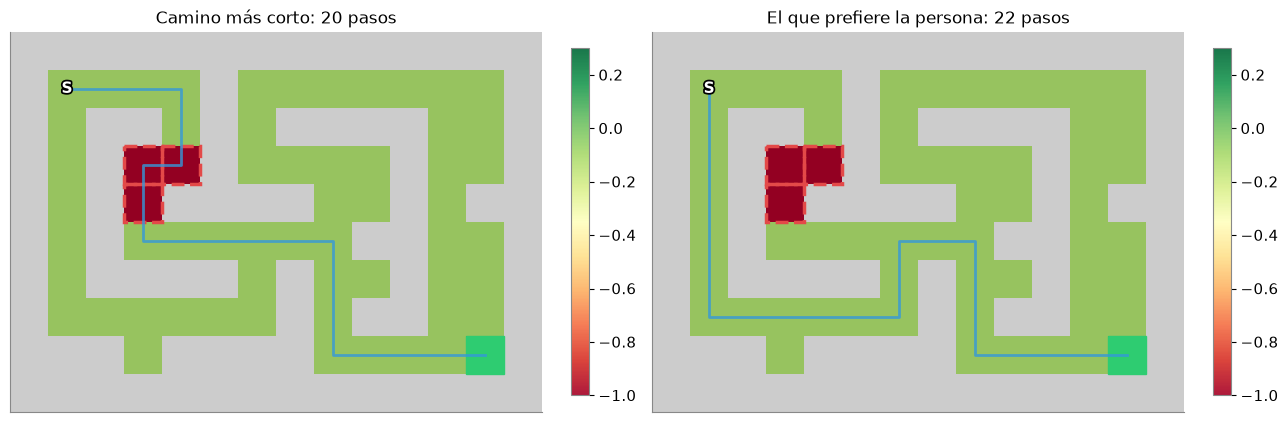

camino más corto: 20 pasos, pasa por 3 derrumbes, retorno con la recompensa escondida = -3.480
camino óptimo:    22 pasos, pasa por 0 derrumbes, retorno con la recompensa escondida = -1.093   (V*(S))


In [4]:
r_solo_salida = np.zeros(env.nS); r_solo_salida[env.goal] = 1.0
_, Q_corto = iteracion_de_valor(r_solo_salida)
pi_corto = politica_greedy(Q_corto)
V_opt, Q_opt = iteracion_de_valor(r_escondida)
pi_opt = politica_greedy(Q_opt)
camino_corto, camino_opt = camino(pi_corto), camino(pi_opt)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
plot_cave(env, values=r_escondida, ax=axs[0], cmap="RdYlGn", clim=(-1, 0.3), path=camino_corto,
          title=f"Camino más corto: {len(camino_corto) - 1} pasos")
plot_cave(env, values=r_escondida, ax=axs[1], cmap="RdYlGn", clim=(-1, 0.3), path=camino_opt,
          title=f"El que prefiere la persona: {len(camino_opt) - 1} pasos")
for ax in axs:
    marcar_derrumbe(ax)
plt.tight_layout(); plt.show()

V_corto_esc = evaluar(pi_corto, r_escondida)[env.start]
print(f"camino más corto: {len(camino_corto) - 1} pasos, pasa por {sum(s in DERRUMBE for s in camino_corto)} derrumbes, "
      f"retorno con la recompensa escondida = {V_corto_esc:.3f}")
print(f"camino óptimo:    {len(camino_opt) - 1} pasos, pasa por {sum(s in DERRUMBE for s in camino_opt)} derrumbes, "
      f"retorno con la recompensa escondida = {V_opt[env.start]:.3f}   (V*(S))")

El camino más corto (el que aprendían los agentes de las clases 4 a 6) cruza los tres derrumbes; el que prefiere la persona da la vuelta por abajo: dos pasos más y ningún derrumbe. Con la recompensa escondida, $V^*(S) = -1{,}09$, contra $-3{,}48$ del camino corto. Pero el agente no conoce esta tabla: tiene que **deducirla de las comparaciones**.

## 2. Comparaciones simuladas

La persona mira **dos pedazos de partida** de 12 pasos que arrancan en la misma casilla (elegida al azar) y dice cuál prefiere. Los pedazos son cortos y al azar, como los clips de video que comparaban las personas en Christiano et al. (2017): así cada pregunta habla de pocas casillas.

La persona no es perfecta. Si $R(A)$ y $R(B)$ son las recompensas escondidas de los dos pedazos, elige A con probabilidad

$$P(A \succ B) = \sigma\!\left(\frac{R(A) - R(B)}{\tau}\right), \qquad \sigma(x) = \frac{1}{1 + e^{-x}},$$

donde $\tau$ es **el ruido de la persona**: con $\tau$ chico casi nunca se equivoca; con $\tau$ grande elige casi a la suerte. Usamos $\tau = 0{,}3$. El ✍️ ejercicio lo cambia.

### Paso 1 — Tres preguntas

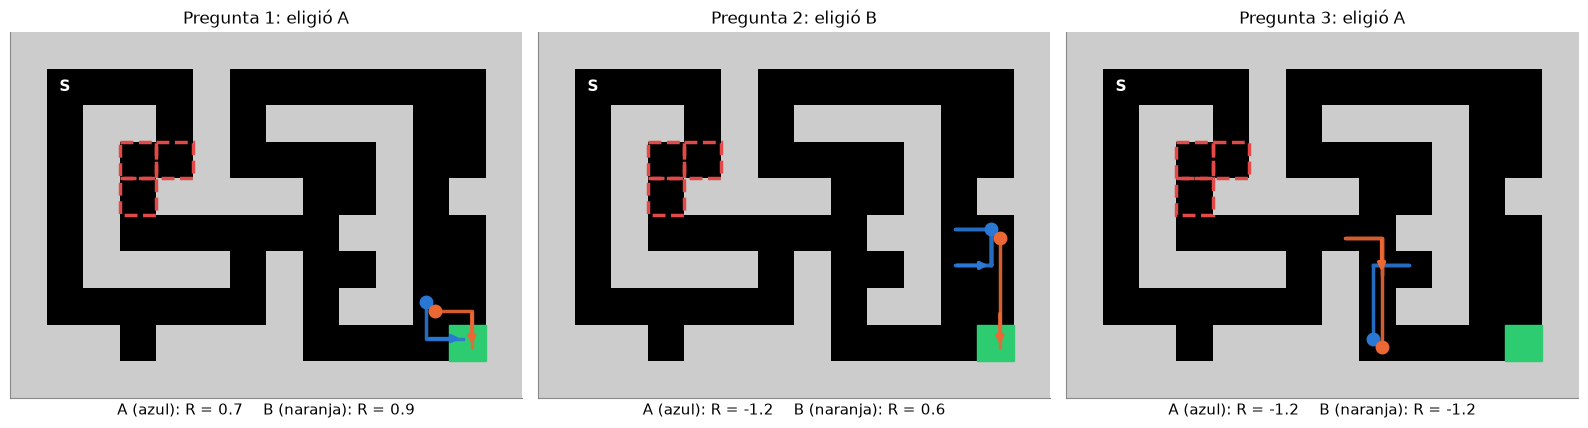

pregunta 1: R(A) = +0.7, R(B) = +0.9, P(A ≻ B) = σ((+0.7 − (+0.9)) / 0.3) = 0.339  →  eligió A
pregunta 2: R(A) = -1.2, R(B) = +0.6, P(A ≻ B) = σ((-1.2 − (+0.6)) / 0.3) = 0.002  →  eligió B
pregunta 3: R(A) = -1.2, R(B) = -1.2, P(A ≻ B) = σ((-1.2 − (-1.2)) / 0.3) = 0.500  →  eligió A


In [5]:
TAU = 0.3
FA_, FB_, Y_, tray_ = comparaciones(300, TAU, semilla=7, guardar=True)
dR = (FA_ - FB_) @ r_escondida
# elegimos tres preguntas típicas: una pareja, una clara y una en la que los dos valen lo mismo
elegidas = [int(np.flatnonzero((np.abs(dR) > 0.15) & (np.abs(dR) < 0.5))[0]),
            int(np.flatnonzero(np.abs(dR) >= 1.5)[0]),
            int(np.flatnonzero(dR == 0)[0])]
FA3, FB3, Y3 = FA_[elegidas], FB_[elegidas], Y_[elegidas]
tray3 = [tray_[i] for i in elegidas]

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for i, ax in enumerate(axs):
    pa, pb = tray3[i]
    RA, RB = FA3[i] @ r_escondida, FB3[i] @ r_escondida
    plot_cave(env, ax=ax, title=f"Pregunta {i + 1}: eligió {'A' if Y3[i] else 'B'}")
    marcar_derrumbe(ax)
    dibujar_trayecto(ax, pa, COL_A, -0.12); dibujar_trayecto(ax, pb, COL_B, 0.12)
    ax.set_xlabel(f"A (azul): R = {RA:.1f}    B (naranja): R = {RB:.1f}")
plt.tight_layout(); plt.show()

for i in range(3):
    RA, RB = FA3[i] @ r_escondida, FB3[i] @ r_escondida
    print(f"pregunta {i + 1}: R(A) = {RA:+.1f}, R(B) = {RB:+.1f}, P(A ≻ B) = σ(({RA:+.1f} − ({RB:+.1f})) / {TAU}) = "
          f"{sigma((RA - RB) / TAU):.3f}  →  eligió {'A' if Y3[i] else 'B'}")

Cada pedazo arranca en el círculo y termina en la punta de flecha; cuando choca contra una pared se queda en la misma casilla (y eso cuenta como volver a entrar). En la pregunta 1 la persona eligió el peor de los dos (le tocaba con probabilidad 0,34): los dos llegan a la salida y la diferencia es de dos pasos. En la 2 la diferencia es enorme (B sale, A no) y en la 3 los dos valen lo mismo y elige a la suerte. La persona no dice cuánto vale cada trayecto: dice **solo cuál prefiere**. El que aprende ve los dos dibujos y la elección, nada más.

### Paso 2 — ¿Por qué comparar y no puntuar?

Una persona que **pone puntaje** («este camino vale 6 de 10») tiene días: hay días en que pone todo más alto y días en que pone todo más bajo. Simulamos eso con un corrimiento al azar por día (con desvío 1) más el mismo ruido $\tau$. Comparamos dos maneras de decidir cuál de dos trayectos es mejor: (a) puntajes de **días distintos**, y (b) una comparación hecha **en el mismo momento**, donde el corrimiento del día se cancela.

In [6]:
rng = np.random.default_rng(1)
FAp, FBp, _ = comparaciones(2000, TAU, semilla=2)
RA_p, RB_p = FAp @ r_escondida, FBp @ r_escondida
distintos = RA_p != RB_p
verdad = RA_p > RB_p

dia_A, dia_B = rng.normal(0, 1, 2000), rng.normal(0, 1, 2000)          # el humor de cada día
puntaje_A = RA_p + dia_A + rng.logistic(0, TAU, 2000)
puntaje_B = RB_p + dia_B + rng.logistic(0, TAU, 2000)
acierto_puntajes = np.mean((puntaje_A > puntaje_B)[distintos] == verdad[distintos])

misma_vez = RA_p + rng.logistic(0, TAU, 2000) > RB_p + rng.logistic(0, TAU, 2000)   # el humor se cancela
acierto_comparar = np.mean(misma_vez[distintos] == verdad[distintos])

print(f"pares con recompensas distintas: {distintos.sum()} de 2000")
print(f"(b) comparar en el mismo momento: el mejor gana en el {acierto_comparar:.1%} de los pares")
print(f"(a) puntajes de días distintos, humor con desvío 1: el mejor gana en el {acierto_puntajes:.1%} de los pares")
for desvio in [0.5, 2.0]:
    pa_ = RA_p + rng.normal(0, desvio, 2000) + rng.logistic(0, TAU, 2000)
    pb_ = RB_p + rng.normal(0, desvio, 2000) + rng.logistic(0, TAU, 2000)
    print(f"(a) puntajes de días distintos, humor con desvío {desvio}: el mejor gana en el "
          f"{np.mean((pa_ > pb_)[distintos] == verdad[distintos]):.1%} de los pares")

pares con recompensas distintas: 930 de 2000
(b) comparar en el mismo momento: el mejor gana en el 70.6% de los pares
(a) puntajes de días distintos, humor con desvío 1: el mejor gana en el 66.9% de los pares
(a) puntajes de días distintos, humor con desvío 0.5: el mejor gana en el 70.2% de los pares
(a) puntajes de días distintos, humor con desvío 2.0: el mejor gana en el 63.9% de los pares


Con la misma persona y el mismo ruido, comparar acierta más que puntuar en días distintos, y la ventaja crece cuanto más cambia el humor de un día a otro: al comparar, lo que cambia afecta a los dos trayectos por igual y se cancela. (Restar dos ruidos logísticos da justamente la $\sigma$ de Bradley-Terry: la persona de la celda (b) es la misma que la de la función `persona`.) Por eso RLHF les pide a las personas **comparar** respuestas y no ponerles nota.

## 3. Bradley-Terry: de la diferencia de recompensas a la probabilidad

El modelo de Bradley y Terry (1952) dice que la probabilidad de preferir A depende **solo de la diferencia** de recompensas:

$$P(A \succ B) = \sigma\big(r(A) - r(B)\big).$$

Si $r(A) = r(B)$, da 0,5 (moneda). Cuanto más le saca A a B, más se acerca a 1. La $\tau$ de nuestra persona solo cambia la escala: $r = R / \tau$.

### Paso 1 — Una cuenta a mano

Tomamos la pregunta 1 de la sección anterior.

R(A) = +0.70   R(B) = +0.90
en unidades de la persona: r(A) = R(A)/τ = +0.70/0.3 = +2.333    r(B) = +0.90/0.3 = +3.000
r(A) − r(B) = -0.667
e^(−(r(A) − r(B))) = 1.9477
P(A ≻ B) = 1 / (1 + 1.9477) = 0.3392
P(B ≻ A) = 1 − 0.3392 = 0.6608

con la misma diferencia en R pero una persona más dudosa (τ = 1):
P(A ≻ B) = σ(-0.20) = 0.4502


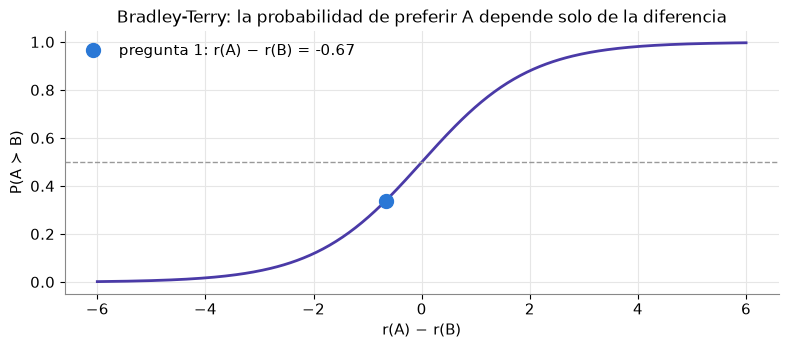

In [7]:
RA, RB = FA3[0] @ r_escondida, FB3[0] @ r_escondida
rA, rB = RA / TAU, RB / TAU
print(f"R(A) = {RA:+.2f}   R(B) = {RB:+.2f}")
print(f"en unidades de la persona: r(A) = R(A)/τ = {RA:+.2f}/{TAU} = {rA:+.3f}    r(B) = {RB:+.2f}/{TAU} = {rB:+.3f}")
print(f"r(A) − r(B) = {rA - rB:+.3f}")
print(f"e^(−(r(A) − r(B))) = {np.exp(-(rA - rB)):.4f}")
print(f"P(A ≻ B) = 1 / (1 + {np.exp(-(rA - rB)):.4f}) = {sigma(rA - rB):.4f}")
print(f"P(B ≻ A) = 1 − {sigma(rA - rB):.4f} = {1 - sigma(rA - rB):.4f}")
print()
print("con la misma diferencia en R pero una persona más dudosa (τ = 1):")
print(f"P(A ≻ B) = σ({RA - RB:+.2f}) = {sigma(RA - RB):.4f}")

x = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, sigma(x), color=COLORES[6])
ax.plot([rA - rB], [sigma(rA - rB)], "o", color=COL_A, ms=10, label=f"pregunta 1: r(A) − r(B) = {rA - rB:.2f}")
ax.axhline(0.5, color="#999", lw=1, ls="--")
ax.set_xlabel("r(A) − r(B)"); ax.set_ylabel("P(A ≻ B)"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Bradley-Terry: la probabilidad de preferir A depende solo de la diferencia")
plt.tight_layout(); plt.show()

### Paso 2 — Al revés: de las elecciones a una recompensa por casilla

Ahora el problema inverso, el que importa: ver muchas elecciones y deducir $r$. Ponemos una recompensa desconocida $\theta_s$ en cada casilla; la de un trayecto es la suma de las casillas a las que entra: $r(A) = \sum_s \theta_s \, \varphi_s(A)$, con $\varphi_s(A)$ = cuántas veces entra a $s$. Entonces

$$P(A \succ B) = \sigma\big(\theta \cdot (\varphi(A) - \varphi(B))\big),$$

que es una **regresión logística** (la de clasificar con dos clases) con entrada $\varphi(A) - \varphi(B)$ y etiqueta «eligió A». La ajustamos por descenso de gradiente sobre la pérdida de entropía cruzada, como una red neuronal de una sola capa. Probamos con 1000 comparaciones.

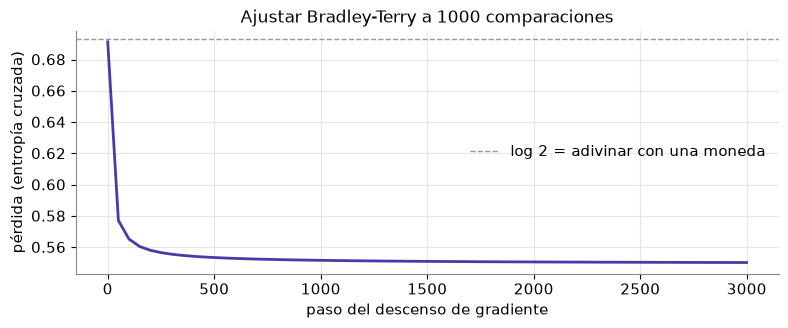

pérdida al empezar (θ = 0): 0.6913   (log 2 = 0.6931)
pérdida al final: 0.5503
el modelo le da más de 0,5 a la opción que eligió la persona en el 66.2% de las 1000 preguntas
en las 562 preguntas donde los trayectos no valían lo mismo: la persona eligió el mejor en el 64.8%, el modelo apuesta por el mejor en el 65.8%
θ de una casilla común (promedio) × τ = -0.039   (escondida: -0.1)
θ de los derrumbes (promedio) × τ    = -0.911   (escondida: -1.0)
θ de la salida × τ                   = +0.980   (escondida: 1.0)


In [8]:
FA, FB, Y = comparaciones(1000, TAU, semilla=0)
theta, perdidas = ajustar_bt(FA, FB, Y)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.r_[np.arange(0, 3000, 50), 2999], perdidas, color=COLORES[6])
ax.axhline(np.log(2), color="#999", ls="--", lw=1, label="log 2 = adivinar con una moneda")
ax.set_xlabel("paso del descenso de gradiente"); ax.set_ylabel("pérdida (entropía cruzada)")
ax.set_title("Ajustar Bradley-Terry a 1000 comparaciones"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

p_fit = sigma((FA - FB) @ theta)
print(f"pérdida al empezar (θ = 0): {perdidas[0]:.4f}   (log 2 = {np.log(2):.4f})")
print(f"pérdida al final: {perdidas[-1]:.4f}")
dR1 = (FA - FB) @ r_escondida; dif = dR1 != 0
print(f"el modelo le da más de 0,5 a la opción que eligió la persona en el {np.mean((p_fit > 0.5) == (Y == 1)):.1%} de las 1000 preguntas")
print(f"en las {dif.sum()} preguntas donde los trayectos no valían lo mismo: la persona eligió el mejor en el {np.mean((Y == 1)[dif] == (dR1 > 0)[dif]):.1%}, "
      f"el modelo apuesta por el mejor en el {np.mean((p_fit > 0.5)[dif] == (dR1 > 0)[dif]):.1%}")
print(f"θ de una casilla común (promedio) × τ = {TAU * theta[(r_escondida == R_PASO)].mean():+.3f}   (escondida: {R_PASO})")
print(f"θ de los derrumbes (promedio) × τ    = {TAU * theta[DERRUMBE].mean():+.3f}   (escondida: {R_DERRUMBE})")
print(f"θ de la salida × τ                   = {TAU * theta[env.goal]:+.3f}   (escondida: {R_SALIDA})")

La pérdida baja desde $\log 2$ (adivinar con una moneda) y el modelo acierta la elección de la persona en dos de cada tres preguntas: no más, porque en muchas los dos trayectos valen lo mismo y la persona tira la moneda. Donde valen distinto, el modelo apuesta por el mejor tan seguido como la persona elige al mejor (alrededor de 65 %): muchas de esas diferencias son de uno o dos pasos, y ahí la persona duda. Lo notable son los números de abajo: **sin haber visto nunca la tabla**, el ajuste deduce que los derrumbes son mucho peores que una casilla común y que la salida es buena.

Un detalle: lo que se aprende es $\theta \approx R/\tau$, la recompensa **en las unidades de la persona**. Multiplicamos por $\tau$ solo para compararla con la escondida, porque acá conocemos $\tau$ (inventamos a la persona). En la vida real no se conoce, pero no importa para elegir: multiplicar todas las recompensas por un número positivo no cambia cuál camino es mejor.

## 4. La recompensa aprendida y la planificación

### Paso 1 — El mapa que se arma con las respuestas

Repetimos el ajuste con 100, 300, 1000 y 3000 comparaciones y dibujamos la recompensa aprendida en cada casilla (multiplicada por $\tau$) al lado de la escondida. Medimos el parecido con la correlación entre las dos (1 = mismo dibujo, sin contar la salida).

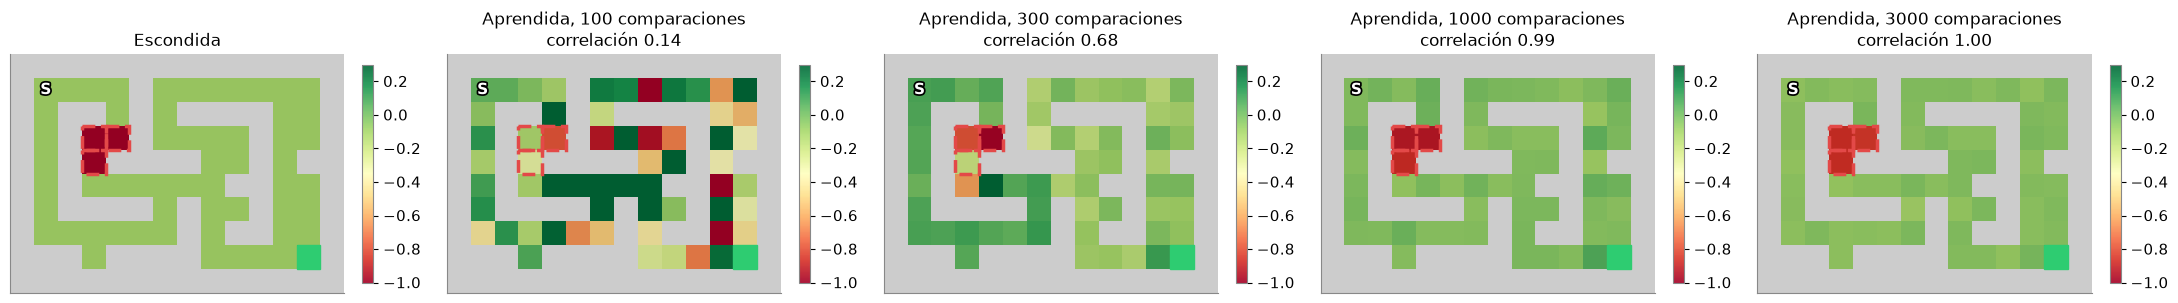

 comparaciones   correlación con la escondida (5 semillas)            error medio por casilla
           100   [0.136 0.379 0.151 0.228 0.245]  media 0.228   0.475
           300   [0.679 0.903 0.846 0.919 0.859]  media 0.841   0.098
          1000   [0.989 0.982 0.976 0.984 0.973]  media 0.981   0.044
          3000   [0.996 0.995 0.995 0.989 0.982]  media 0.992   0.036


In [9]:
NS = [100, 300, 1000, 3000]
SEMILLAS = range(5)
aprendidas = {(N, sem): TAU * ajustar_bt(*comparaciones(N, TAU, semilla=sem))[0] for N in NS for sem in SEMILLAS}

fig, axs = plt.subplots(1, 5, figsize=(22, 4.0))
plot_cave(env, values=r_escondida, ax=axs[0], cmap="RdYlGn", clim=(-1, 0.3), title="Escondida")
marcar_derrumbe(axs[0])
for ax, N in zip(axs[1:], NS):
    r_ = aprendidas[(N, 0)]
    plot_cave(env, values=r_, ax=ax, cmap="RdYlGn", clim=(-1, 0.3), title=f"Aprendida, {N} comparaciones\ncorrelación {correlacion(r_):.2f}")
    marcar_derrumbe(ax)
plt.tight_layout(); plt.show()

print(f"{'comparaciones':>14s}   correlación con la escondida (5 semillas)            error medio por casilla")
for N in NS:
    cs = [correlacion(aprendidas[(N, s)]) for s in SEMILLAS]
    es = [np.abs(aprendidas[(N, s)] - r_escondida)[NO_SALIDA].mean() for s in SEMILLAS]
    print(f"{N:>14d}   {np.round(cs, 3)}  media {np.mean(cs):.3f}   {np.mean(es):.3f}")

Con 100 comparaciones el mapa es casi ruido; con 300 ya aparecen los derrumbes (no todos) y algunas casillas comunes quedan por encima de 0 (verde oscuro); con 1000 y 3000 se parece mucho al escondido.

### Paso 2 — Dónde se equivoca: donde nadie comparó

Para cada casilla contamos en cuántas preguntas los dos pedazos la visitaron **una cantidad distinta de veces** (si los dos pasan igual, la pregunta no dice nada de esa casilla), y lo ponemos al lado del error, con 300 comparaciones.

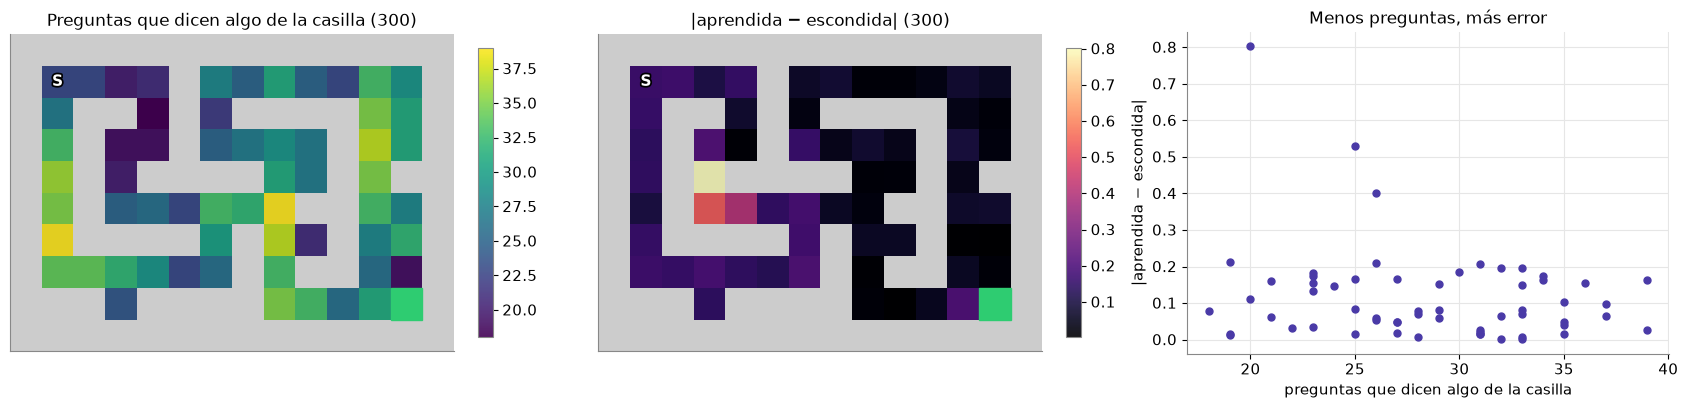

mediana de preguntas por casilla: 28
error medio en las casillas con menos preguntas que la mediana: 0.152
error medio en las casillas con más (o igual):                   0.085


In [10]:
FA300, FB300, _ = comparaciones(300, TAU, semilla=0)
informan = (FA300 != FB300).sum(axis=0)
error300 = np.abs(aprendidas[(300, 0)] - r_escondida)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
plot_cave(env, values=informan, ax=axs[0], cmap="viridis", title="Preguntas que dicen algo de la casilla (300)")
plot_cave(env, values=error300, ax=axs[1], cmap="magma", title="|aprendida − escondida| (300)")
axs[2].scatter(informan[NO_SALIDA], error300[NO_SALIDA], color=COLORES[6], s=25)
axs[2].set_xlabel("preguntas que dicen algo de la casilla"); axs[2].set_ylabel("|aprendida − escondida|")
axs[2].set_title("Menos preguntas, más error")
plt.tight_layout(); plt.show()

poco = informan[NO_SALIDA] < np.median(informan[NO_SALIDA])
print(f"mediana de preguntas por casilla: {np.median(informan[NO_SALIDA]):.0f}")
print(f"error medio en las casillas con menos preguntas que la mediana: {error300[NO_SALIDA][poco].mean():.3f}")
print(f"error medio en las casillas con más (o igual):                   {error300[NO_SALIDA][~poco].mean():.3f}")

En promedio, las casillas con menos preguntas tienen casi el doble de error, pero la relación es ruidosa: con 300 comparaciones ninguna casilla tiene muchas. Los errores más grandes están en los derrumbes y al lado: cuando un pedazo pasa por varias casillas vecinas y pierde, la regresión tiene que adivinar cuál de ellas tuvo la culpa, y con pocas preguntas reparte mal.

### Paso 3 — Planificar con la recompensa aprendida

Ahora el paso de RL: con la recompensa aprendida calculamos la mejor política por **iteración de valor** (clase 4), como si fuera la verdadera, y medimos qué tan buena es **con la recompensa escondida**. La referencia es $V^*(S) = -1{,}09$; quedarse para siempre en una casilla común vale $-0{,}1/(1-\gamma) = -10$ (calculamos sin el tope de 200 pasos).

V*(S) con la recompensa escondida = -1.093
 comparaciones   retorno verdadero desde S de la política planificada (5 semillas)   ¿llega a la salida?
           100   [-12.57 -10.   -10.   -10.   -10.  ]   0 de 5
           300   [-10. -10. -10. -10. -10.]   0 de 5


          1000   [-10.    -1.09 -10.    -1.09  -1.09]   3 de 5
          3000   [-1.09 -1.09 -1.09 -1.09 -1.09]   5 de 5


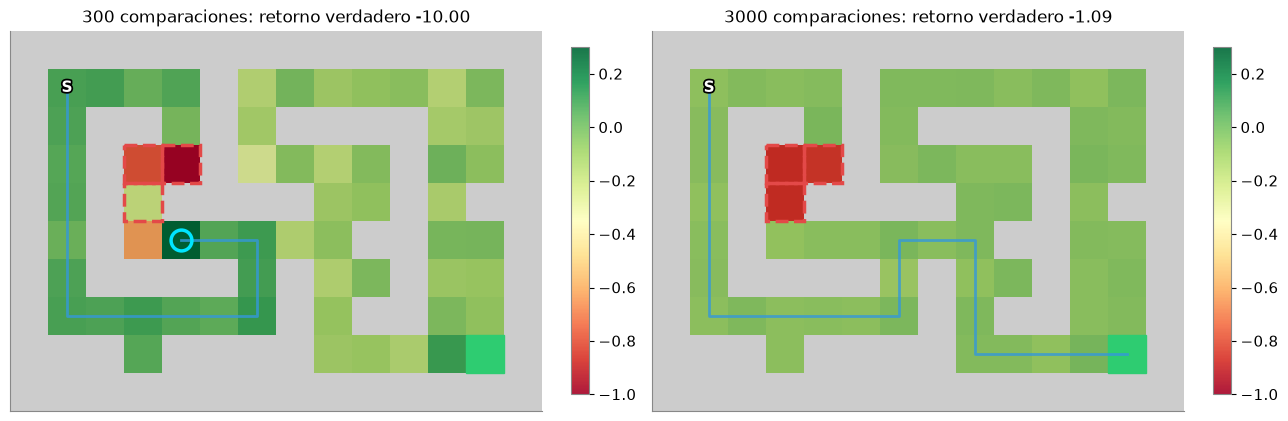

con 300 comparaciones (semilla 0) el plan termina en la casilla (5, 4): aprendida = +0.300, escondida = -0.100


In [11]:
def plan_greedy(r_aprendida):
    _, Q_ = iteracion_de_valor(r_aprendida)
    return politica_greedy(Q_)

print(f"V*(S) con la recompensa escondida = {V_opt[env.start]:.3f}")
print(f"{'comparaciones':>14s}   retorno verdadero desde S de la política planificada (5 semillas)   ¿llega a la salida?")
retorno_greedy = {}
for N in NS:
    vs, sale = [], []
    for s in SEMILLAS:
        pi_ = plan_greedy(aprendidas[(N, s)])
        vs.append(evaluar(pi_, r_escondida)[env.start]); sale.append(camino(pi_, n=200)[-1] == env.goal)
    retorno_greedy[N] = vs
    print(f"{N:>14d}   {np.round(vs, 2)}   {sum(sale)} de 5")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, N in zip(axs, [300, 3000]):
    r_ = aprendidas[(N, 0)]; pi_ = plan_greedy(r_); path = camino(pi_)
    plot_cave(env, values=r_, ax=ax, cmap="RdYlGn", clim=(-1, 0.3), path=path, mark=path[-1] if path[-1] != env.goal else None,
              title=f"{N} comparaciones: retorno verdadero {evaluar(pi_, r_escondida)[env.start]:.2f}")
    marcar_derrumbe(ax)
plt.tight_layout(); plt.show()

r_ = aprendidas[(300, 0)]; atasco = camino(plan_greedy(r_))[-1]
print(f"con 300 comparaciones (semilla 0) el plan termina en la casilla {env.free[atasco]}: "
      f"aprendida = {r_[atasco]:+.3f}, escondida = {r_escondida[atasco]:+.3f}")

Con 100 y 300 comparaciones, el plan **no sale nunca** (con 1000, en 3 de 5 semillas): va hasta una casilla donde la recompensa aprendida quedó un poquito por encima de cero (círculo celeste) y se queda ahí chocando contra la pared para siempre, cobrando ese premio inventado en cada paso. Con la recompensa escondida esa casilla cuesta −0,1 por paso, y el retorno verdadero es −10 (o peor, si antes pasa por un derrumbe). Con 3000 comparaciones el mapa es lo bastante bueno y el plan encuentra el camino de la persona, con el retorno óptimo, en las 5 semillas.

Es **la trampa de la recompensa de la clase 2**, pero ahora la recompensa mal escrita la escribió una máquina a partir de nuestras respuestas. Un planificador que maximiza sin dudar encuentra cualquier error a favor. Las dos secciones que siguen tratan de eso.

## 5. RLHF en chico: imitar, aprender la recompensa, optimizar con penalización

El aprendizaje por refuerzo con preferencias humanas (*reinforcement learning from human feedback*, RLHF) de Christiano et al. (2017) y Ouyang et al. (2022) tiene tres etapas. Las armamos con la cueva:

1. **Imitar** (clase 10): una política inicial $\pi_{\text{ref}}$ que copia partidas grabadas. En los modelos de lenguaje es el ajuste supervisado con ejemplos escritos por personas.
2. **Aprender la recompensa**: Bradley-Terry con comparaciones de personas (lo que hicimos en las secciones 3 y 4). Usamos 300 comparaciones: un modelo de recompensa con errores.
3. **Optimizar con una penalización por alejarse**: maximizar la recompensa aprendida **menos** $\beta$ veces cuánto se aleja la política de $\pi_{\text{ref}}$, medido con la divergencia KL:

$$\text{objetivo} = \mathbb{E}\Big[\sum_t \gamma^t \big(\hat r_t - \beta\, \mathrm{KL}(\pi(\cdot \mid s_t) \,\|\, \pi_{\text{ref}}(\cdot \mid s_t))\big)\Big].$$

En los modelos de lenguaje este paso se hace con PPO (clase 11). Acá la cueva es chica y lo resolvemos exacto con una iteración de valor «suave»: la mejor política queda $\pi(a \mid s) \propto \pi_{\text{ref}}(a \mid s)\, e^{Q(s,a)/\beta}$, la de referencia empujada hacia las flechas que la recompensa aprendida considera mejores.

### Paso 1 — Imitar

In [12]:
grabadas = partidas_grabadas(200, semilla=0)
pi_ref = imitar(grabadas)
V_ref_esc = evaluar(pi_ref, r_escondida)[env.start]
print(f"{len(grabadas)} partidas grabadas, {sum(len(p) for p in grabadas)} pasos")
print("π_ref en S: " + ", ".join(f"{ACTION_NAMES[a]} {pi_ref[env.start, a]:.2f}" for a in range(4)))
print(f"retorno verdadero de π_ref desde S = {V_ref_esc:.3f}   (camino corto: {V_corto_esc:.3f}, óptimo: {V_opt[env.start]:.3f})")

200 partidas grabadas, 2248 pasos
π_ref en S: ↑ 0.06, → 0.83, ↓ 0.06, ← 0.06
retorno verdadero de π_ref desde S = -3.909   (camino corto: -3.480, óptimo: -1.093)


La gente que grabó las partidas quería salir rápido: en S, $\pi_{\text{ref}}$ elige la flecha a la derecha (la del camino corto, por los derrumbes) mucho más que la de abajo. Su retorno verdadero es incluso un poco peor que el del camino corto, porque a veces da pasos de más.

### Paso 2 — Aprender la recompensa y optimizar con penalización

Con la recompensa aprendida de 300 comparaciones, optimizamos con $\beta = 0{,}3$ y lo comparamos con optimizar sin penalización (la iteración de valor de la sección 4), en 5 semillas de comparaciones.

 semilla    π_ref  sin penalización  con penalización  KL desde S
       0    -3.91            -10.00             -1.55        3.49
       1    -3.91            -10.00             -1.27        3.42
       2    -3.91            -10.00             -1.28        3.40
       3    -3.91            -10.00             -1.27        3.43
       4    -3.91            -10.00             -1.30        3.37
   media    -3.91            -10.00             -1.33      (óptimo: -1.09)


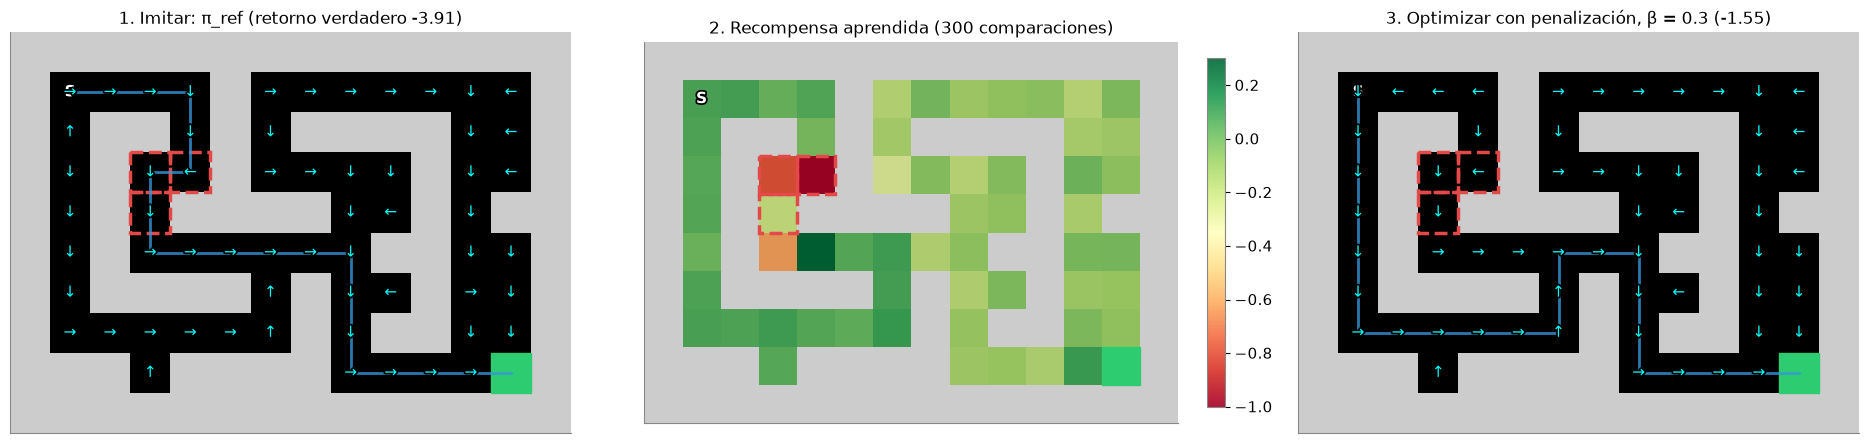

π en S después de RLHF: ↑ 0.07, → 0.30, ↓ 0.55, ← 0.07


In [13]:
BETA = 0.3
print(f"{'semilla':>8s} {'π_ref':>8s} {'sin penalización':>17s} {'con penalización':>17s} {'KL desde S':>11s}")
rlhf = []
for s in SEMILLAS:
    r_ = aprendidas[(300, s)]
    pi_pen = planificar_con_penalizacion(r_, BETA, pi_ref)
    v_sin = evaluar(plan_greedy(r_), r_escondida)[env.start]
    v_con = evaluar(pi_pen, r_escondida)[env.start]
    rlhf.append((v_sin, v_con)); print(f"{s:>8d} {V_ref_esc:>8.2f} {v_sin:>17.2f} {v_con:>17.2f} {kl_desde_S(pi_pen, pi_ref):>11.2f}")
rlhf = np.array(rlhf)
print(f"{'media':>8s} {V_ref_esc:>8.2f} {rlhf[:, 0].mean():>17.2f} {rlhf[:, 1].mean():>17.2f}      (óptimo: {V_opt[env.start]:.2f})")

r_ = aprendidas[(300, 0)]; pi_pen = planificar_con_penalizacion(r_, BETA, pi_ref)
fig, axs = plt.subplots(1, 3, figsize=(19, 4.4))
plot_cave(env, policy=pi_ref.argmax(axis=1), path=camino(pi_ref), ax=axs[0],
          title=f"1. Imitar: π_ref (retorno verdadero {V_ref_esc:.2f})")
plot_cave(env, values=r_, ax=axs[1], cmap="RdYlGn", clim=(-1, 0.3), title="2. Recompensa aprendida (300 comparaciones)")
plot_cave(env, policy=pi_pen.argmax(axis=1), path=camino(pi_pen), ax=axs[2],
          title=f"3. Optimizar con penalización, β = {BETA} ({evaluar(pi_pen, r_escondida)[env.start]:.2f})")
for ax in axs:
    marcar_derrumbe(ax)
plt.tight_layout(); plt.show()
print("π en S después de RLHF: " + ", ".join(f"{ACTION_NAMES[a]} {pi_pen[env.start, a]:.2f}" for a in range(4)))

Las flechas muestran la acción más probable en cada casilla y la línea, el camino más probable desde S. Con la misma recompensa aprendida con errores, la penalización cambia todo: sin ella la política se va a vivir a una casilla con premio inventado; con ella se mueve **solo donde la recompensa aprendida tiene argumentos fuertes** (en S pasa a preferir la flecha de abajo, que esquiva los derrumbes) y en el resto sigue haciendo lo que hacía $\pi_{\text{ref}}$, que por lo menos sale. El retorno verdadero queda cerca del óptimo.

## 6. Sobreoptimización y penalización

¿Cuánto conviene optimizar? Barremos $\beta$ desde muy grande (la política casi no se mueve de $\pi_{\text{ref}}$) hasta casi 0 (optimizar sin freno) y medimos, desde S, el retorno con la **recompensa aprendida** (lo que cree el optimizador) y con la **escondida** (lo que de verdad quería la persona). Gao, Schulman y Hilton (2023) midieron esta curva con modelos de lenguaje: al principio las dos suben juntas; si se sigue optimizando, la aprendida sigue subiendo y la verdadera baja.

### Paso 1 — Barrer la fuerza de la optimización, con 300 comparaciones

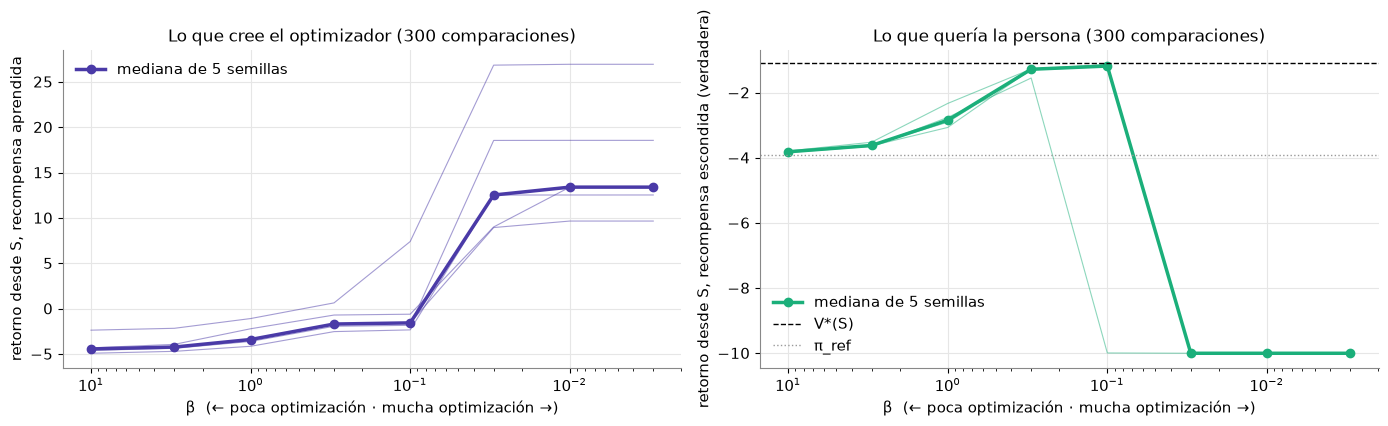

      β  aprendida (mediana)  verdadera (mediana)                  verdadera, 5 semillas  KL (mediana)
     10                -4.43                -3.82        [-3.84 -3.82 -3.81 -3.79 -3.82]           0.0
      3                -4.22                -3.62        [-3.65 -3.62 -3.63 -3.52 -3.62]           0.1
      1                -3.39                -2.85        [-2.76 -2.85 -3.07 -2.33 -2.91]           0.6
    0.3                -1.69                -1.28        [-1.55 -1.27 -1.28 -1.27 -1.3 ]           3.4
    0.1                -1.56                -1.18        [-9.99 -1.15 -1.13 -1.18 -1.2 ]           4.1
   0.03                12.53               -10.00             [-10. -10. -10. -10. -10.]         309.6
   0.01                13.40               -10.00             [-10. -10. -10. -10. -10.]         326.8
  0.003                13.40               -10.00             [-10. -10. -10. -10. -10.]         326.8

mejor β (mediana de la verdadera): 0.1 → verdadera -1.18; con β = 0.003 

In [14]:
BETAS = np.array([10, 3, 1, 0.3, 0.1, 0.03, 0.01, 0.003])

def barrido(N):
    apr, ver, kl = [], [], []
    for s in SEMILLAS:
        r_ = aprendidas[(N, s)]; fila = [[], [], []]
        for b in BETAS:
            pi_ = planificar_con_penalizacion(r_, b, pi_ref)
            fila[0].append(evaluar(pi_, r_)[env.start]); fila[1].append(evaluar(pi_, r_escondida)[env.start])
            fila[2].append(kl_desde_S(pi_, pi_ref))
        apr.append(fila[0]); ver.append(fila[1]); kl.append(fila[2])
    return np.array(apr), np.array(ver), np.array(kl)

apr300, ver300, kl300 = barrido(300)

def dibujar_barrido(apr, ver, N):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
    for ax, datos, col, nombre in [(axs[0], apr, COL_APR, "aprendida"), (axs[1], ver, COL_VER, "escondida (verdadera)")]:
        for fila in datos:
            ax.plot(BETAS, fila, color=col, lw=0.8, alpha=0.5)
        ax.plot(BETAS, np.median(datos, axis=0), "o-", color=col, lw=2.5, label="mediana de 5 semillas")
        ax.set_xscale("log"); ax.invert_xaxis(); ax.set_xlabel("β  (← poca optimización · mucha optimización →)")
        ax.set_ylabel(f"retorno desde S, recompensa {nombre}"); ax.legend(frameon=False)
    axs[1].axhline(V_opt[env.start], color="k", ls="--", lw=1, label="V*(S)")
    axs[1].axhline(V_ref_esc, color="#999", ls=":", lw=1, label="π_ref")
    axs[1].legend(frameon=False)
    axs[0].set_title(f"Lo que cree el optimizador ({N} comparaciones)")
    axs[1].set_title(f"Lo que quería la persona ({N} comparaciones)")
    plt.tight_layout(); plt.show()

dibujar_barrido(apr300, ver300, 300)

def tabla_barrido(apr, ver, kl):
    print(f"{'β':>7s} {'aprendida (mediana)':>20s} {'verdadera (mediana)':>20s} {'verdadera, 5 semillas':>38s} {'KL (mediana)':>13s}")
    for j, b in enumerate(BETAS):
        print(f"{b:>7g} {np.median(apr[:, j]):>20.2f} {np.median(ver[:, j]):>20.2f}   {str(np.round(ver[:, j], 2)):>36s} {np.median(kl[:, j]):>13.1f}")

tabla_barrido(apr300, ver300, kl300)
j_mejor = np.argmax(np.median(ver300, axis=0))
print(f"\nmejor β (mediana de la verdadera): {BETAS[j_mejor]:g} → verdadera {np.median(ver300[:, j_mejor]):.2f}; "
      f"con β = {BETAS[-1]:g} → verdadera {np.median(ver300[:, -1]):.2f}, aprendida {np.median(apr300[:, -1]):.1f}")

Es la curva de la sobreoptimización. Con $\beta$ grande la política es casi $\pi_{\text{ref}}$ y las dos recompensas dicen lo mismo: no muy bueno. Al bajar $\beta$ las dos mejoran juntas: la política aprende a esquivar los derrumbes y el retorno verdadero se acerca a $V^*(S)$. Pero si se sigue bajando, **la aprendida pega un salto y la verdadera se desploma a −10** (en una semilla, ya con $\beta = 0{,}1$): el optimizador encontró la casilla con el premio inventado y se quedó ahí. La columna KL muestra el precio: para llegar a esa casilla la política tiene que alejarse muchísimo de $\pi_{\text{ref}}$.

La penalización por alejarse funciona como un freno: deja a la política cerca de lo que hacía la política imitada, que por lo menos sale de la cueva, y no la deja ir a buscar los errores del modelo. (En el RLHF real hay una razón más: las comparaciones se hacen con respuestas de $\pi_{\text{ref}}$, así que cerca de ella el modelo de recompensa está mejor entrenado. Acá los pedazos salen de casillas y flechas al azar.)

### Paso 2 — Con más comparaciones, el modelo de recompensa aguanta más

Mismo barrido con 3000 comparaciones.

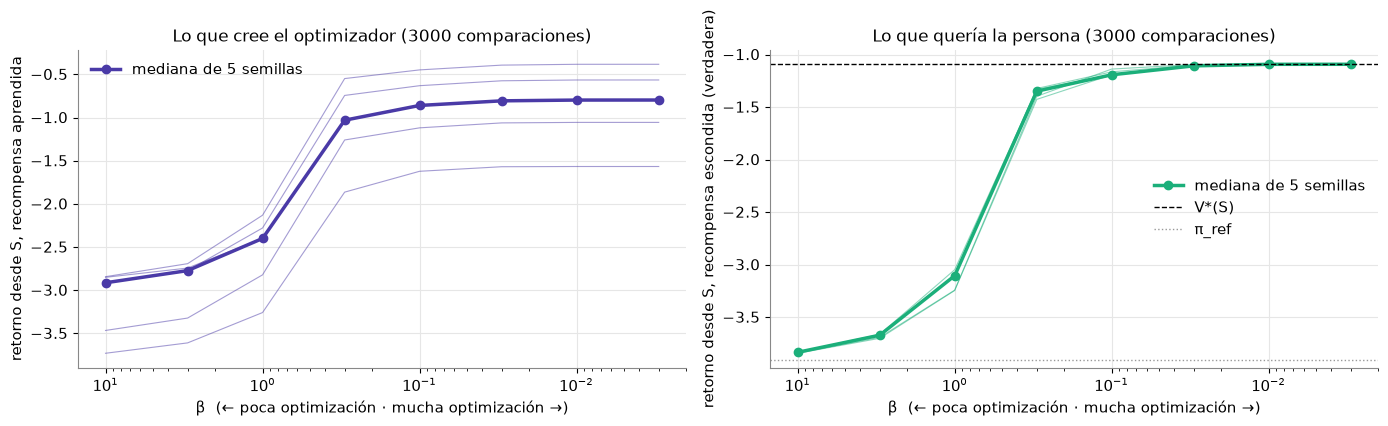

      β  aprendida (mediana)  verdadera (mediana)                  verdadera, 5 semillas  KL (mediana)
     10                -2.91                -3.83        [-3.83 -3.83 -3.83 -3.84 -3.84]           0.0
      3                -2.77                -3.67        [-3.67 -3.67 -3.66 -3.69 -3.7 ]           0.0
      1                -2.40                -3.11        [-3.11 -3.1  -3.05 -3.24 -3.25]           0.4
    0.3                -1.03                -1.35        [-1.35 -1.32 -1.33 -1.4  -1.43]           3.2
    0.1                -0.86                -1.19        [-1.19 -1.17 -1.19 -1.14 -1.19]           3.8
   0.03                -0.81                -1.11        [-1.11 -1.1  -1.11 -1.1  -1.11]           4.7
   0.01                -0.80                -1.09        [-1.09 -1.09 -1.09 -1.09 -1.09]           5.2
  0.003                -0.80                -1.09        [-1.09 -1.09 -1.09 -1.09 -1.09]           5.2


In [15]:
apr3000, ver3000, kl3000 = barrido(3000)
dibujar_barrido(apr3000, ver3000, 3000)
tabla_barrido(apr3000, ver3000, kl3000)

Con 3000 comparaciones el mapa aprendido ya no tiene casillas con premio inventado (sección 4) y optimizar fuerte no rompe nada: la verdadera sube hasta el óptimo y se queda ahí. Un modelo de recompensa con más datos aguanta más optimización antes de que aparezca la caída; Gao et al. encontraron lo mismo con modelos de recompensa más grandes. En la práctica nunca se sabe bien dónde están los errores del modelo, y por eso RLHF siempre lleva la penalización.

## 7. DPO en un caso chico

RLHF necesita dos pasos: aprender un modelo de recompensa y después optimizar con RL. La optimización directa de preferencias (*direct preference optimization*, DPO) de Rafailov et al. (2023) los junta en uno: ajusta la política directamente con las comparaciones, de manera que la respuesta preferida gane probabilidad frente a la otra, **relativa a la política de referencia**.

Para verlo usamos un *bandit* (clase 7): a la pregunta «¿por dónde salgo?» la política responde con una de **cuatro rutas enteras** desde S. La persona compara pares de rutas con la recompensa escondida. Acá usamos una persona más dudosa, $\tau = 1$, para que algunas comparaciones sean parejas.

### Paso 1 — Las cuatro respuestas y la política de referencia

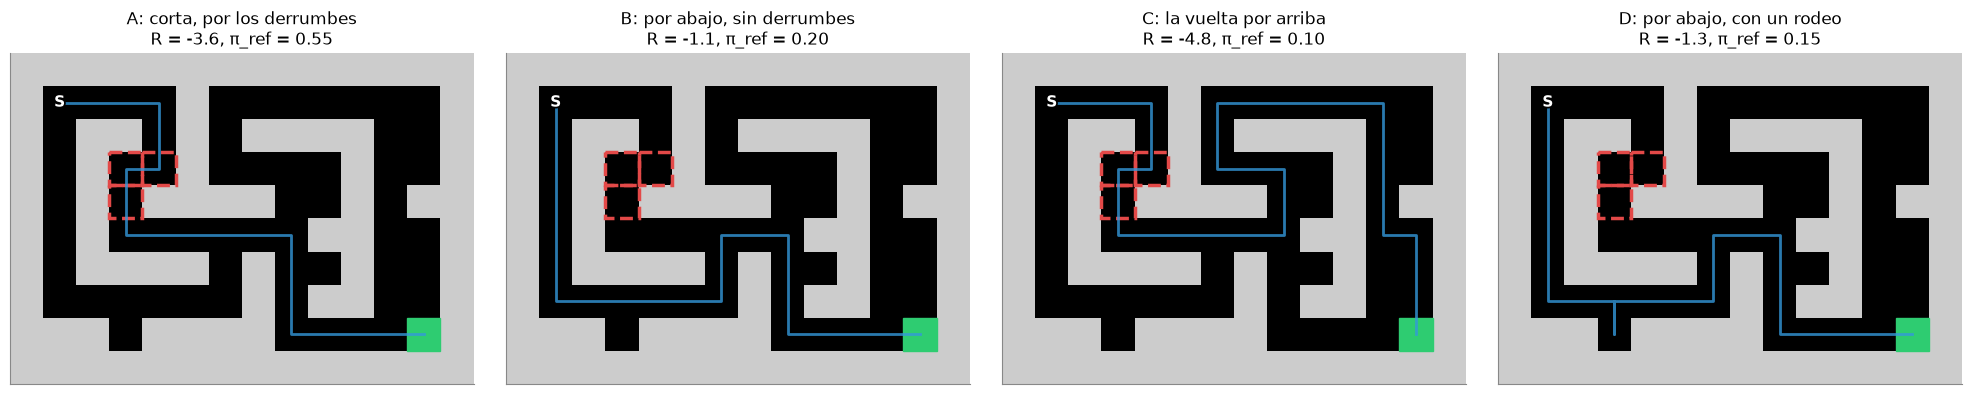

A: corta, por los derrumbes     20 pasos   R = -3.60   π_ref = 0.55
B: por abajo, sin derrumbes     22 pasos   R = -1.10   π_ref = 0.20
C: la vuelta por arriba         32 pasos   R = -4.80   π_ref = 0.10
D: por abajo, con un rodeo      24 pasos   R = -1.30   π_ref = 0.15


In [16]:
def ruta_por(*puntos):
    # camino más corto que pasa por una lista de casillas (búsqueda en anchura entre cada par)
    from collections import deque
    path = [env.start]
    for destino in [env.pos2s[p] for p in puntos] + [env.goal]:
        previo = {path[-1]: None}; cola = deque([path[-1]])
        while cola:
            s = cola.popleft()
            for a in range(env.nA):
                s2 = int(NEXT[s, a])
                if s2 not in previo:
                    previo[s2] = s; cola.append(s2)
        tramo = []; s = destino
        while s != path[-1]:
            tramo.append(s); s = previo[s]
        path += tramo[::-1]
    return path

RUTAS = {"A: corta, por los derrumbes": camino_corto,
         "B: por abajo, sin derrumbes": camino_opt,
         "C: la vuelta por arriba": ruta_por((1, 9)),
         "D: por abajo, con un rodeo": ruta_por((8, 3))}
NOMBRES = list(RUTAS)
R_rutas = np.array([conteo(p) @ r_escondida for p in RUTAS.values()])
p_ref = np.array([0.55, 0.20, 0.10, 0.15])       # lo que respondía la política imitada

fig, axs = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, (nombre, p), R_, q in zip(axs, RUTAS.items(), R_rutas, p_ref):
    plot_cave(env, ax=ax, path=p, title=f"{nombre}\nR = {R_:.1f}, π_ref = {q:.2f}")
    marcar_derrumbe(ax)
plt.tight_layout(); plt.show()
for nombre, p, R_, q in zip(NOMBRES, RUTAS.values(), R_rutas, p_ref):
    print(f"{nombre:30s} {len(p) - 1:>3d} pasos   R = {R_:+.2f}   π_ref = {q:.2f}")

La política de referencia (inventada, pero en el espíritu de la sección 5) responde casi siempre la ruta A, la peor para la persona. La preferida es B.

### Paso 2 — La pérdida de DPO

Juntamos 1000 comparaciones: dos rutas distintas sacadas de $\pi_{\text{ref}}$, y la persona dice cuál prefiere ($y_w$ la ganadora, $y_l$ la perdedora). La pérdida de DPO para cada comparación es

$$-\log \sigma\Big(\beta \Big[\log \frac{\pi(y_w)}{\pi_{\text{ref}}(y_w)} - \log \frac{\pi(y_l)}{\pi_{\text{ref}}(y_l)}\Big]\Big).$$

Es Bradley-Terry otra vez, con una diferencia: en lugar de una recompensa aprendida aparte, la «recompensa» de cada respuesta es $\beta \log \frac{\pi(y)}{\pi_{\text{ref}}(y)}$, **cuánto más probable la hace la política que la referencia**. Bajar la pérdida empuja hacia arriba a la ganadora y hacia abajo a la perdedora, siempre medidas contra la referencia. No hay que derivar nada más: la ajustamos por descenso de gradiente sobre los logits de la política, empezando en $\pi = \pi_{\text{ref}}$.

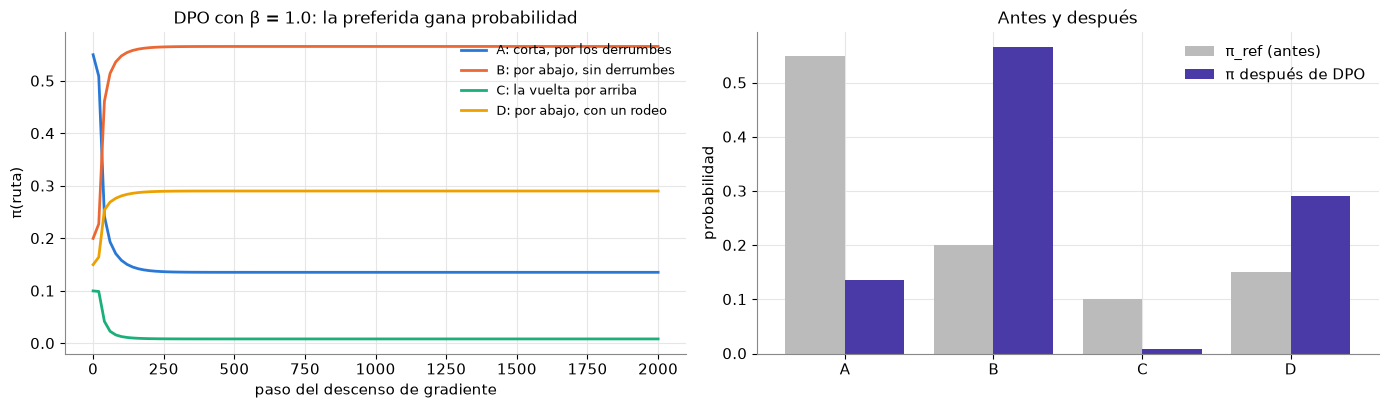

comparaciones ganadas por cada ruta: A 204/850, B 441/498, C 52/279, D 303/373
ruta                            antes (π_ref)  después (DPO)
A: corta, por los derrumbes             0.550          0.135
B: por abajo, sin derrumbes             0.200          0.566
C: la vuelta por arriba                 0.100          0.009
D: por abajo, con un rodeo              0.150          0.290


In [17]:
TAU_DPO = 1.0

def preferencias_rutas(n, semilla):
    rng = np.random.default_rng(semilla); ganadoras, perdedoras = [], []
    for _ in range(n):
        i, j = rng.choice(4, size=2, replace=False, p=p_ref)
        if rng.random() < sigma((R_rutas[i] - R_rutas[j]) / TAU_DPO):
            ganadoras.append(i); perdedoras.append(j)
        else:
            ganadoras.append(j); perdedoras.append(i)
    return np.array(ganadoras), np.array(perdedoras)

def dpo(ganadoras, perdedoras, beta, pasos=2000, lr=None):
    # Logits z: π = softmax(z). log π(y_w) − log π(y_l) = z_w − z_l (la normalización se cancela).
    lr = 0.5 / beta**2 if lr is None else lr        # paso más largo si β es chico (el empuje viene multiplicado por β)
    z_ref = np.log(p_ref); z = z_ref.copy(); historia = [p_ref.copy()]; n = len(ganadoras)
    for k in range(pasos):
        u = beta * ((z[ganadoras] - z[perdedoras]) - (z_ref[ganadoras] - z_ref[perdedoras]))
        g = beta * (1 - sigma(u)) / n               # cuánto empujar en cada comparación
        grad = np.zeros(4)
        np.add.at(grad, ganadoras, -g); np.add.at(grad, perdedoras, g)
        z -= lr * grad
        if k % 20 == 0:
            historia.append(np.exp(z) / np.exp(z).sum())
    return np.exp(z) / np.exp(z).sum(), np.array(historia)

BETA_DPO = 1.0
gan, per = preferencias_rutas(1000, semilla=0)
p_dpo, hist = dpo(gan, per, BETA_DPO)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for i in range(4):
    axs[0].plot(np.arange(len(hist)) * 20, hist[:, i], color=COLORES[i], label=NOMBRES[i])
axs[0].set_xlabel("paso del descenso de gradiente"); axs[0].set_ylabel("π(ruta)"); axs[0].legend(frameon=False, fontsize=9)
axs[0].set_title(f"DPO con β = {BETA_DPO}: la preferida gana probabilidad")
x = np.arange(4)
axs[1].bar(x - 0.2, p_ref, width=0.4, color="#bbbbbb", label="π_ref (antes)")
axs[1].bar(x + 0.2, p_dpo, width=0.4, color=COLORES[6], label="π después de DPO")
axs[1].set_xticks(x, ["A", "B", "C", "D"]); axs[1].set_ylabel("probabilidad"); axs[1].legend(frameon=False)
axs[1].set_title("Antes y después")
plt.tight_layout(); plt.show()

print(f"comparaciones ganadas por cada ruta: " + ", ".join(f"{'ABCD'[i]} {np.sum(gan == i)}/{np.sum(gan == i) + np.sum(per == i)}" for i in range(4)))
print(f"{'ruta':30s} {'antes (π_ref)':>14s} {'después (DPO)':>14s}")
for i in range(4):
    print(f"{NOMBRES[i]:30s} {p_ref[i]:>14.3f} {p_dpo[i]:>14.3f}")

La ruta B, que la política de referencia respondía una de cada cinco veces, pasa a ser la más probable (de 0,20 a 0,57), y la A baja de 0,55 a 0,14. La D, casi tan buena como la B para la persona, también sube. No hubo modelo de recompensa ni RL: solo la pérdida de DPO sobre las comparaciones.

### Paso 3 — DPO llega adonde llegaría RLHF

En un bandit, la mejor política del objetivo de RLHF (recompensa menos $\beta$ veces la KL con la referencia) tiene una fórmula: $\pi(y) \propto \pi_{\text{ref}}(y)\, e^{r(y)/\beta}$. Comparamos tres cosas: DPO, el camino de RLHF en dos pasos (ajustar Bradley-Terry a las mismas 1000 comparaciones y usar esa fórmula con la recompensa aprendida) y la misma fórmula con la recompensa escondida en unidades de la persona ($R/\tau$), que sería lo ideal. Y probamos dos valores de $\beta$, en 5 semillas de comparaciones.

In [18]:
def rlhf_bandit(ganadoras, perdedoras, beta, pasos=5000, lr=2.0):
    # 1) modelo de recompensa: Bradley-Terry con una recompensa por ruta; 2) la mejor política con penalización KL
    r = np.zeros(4); n = len(ganadoras)
    for _ in range(pasos):
        g = (1 - sigma(r[ganadoras] - r[perdedoras])) / n
        grad = np.zeros(4); np.add.at(grad, ganadoras, -g); np.add.at(grad, perdedoras, g)
        r -= lr * grad
    q = p_ref * np.exp(r / beta)
    return q / q.sum()

print(f"{'β':>4s} {'semilla':>8s} {'π(B): DPO':>10s} {'RLHF en 2 pasos':>16s} {'ideal':>7s}    π de DPO (A, B, C, D)")
for beta in [1.0, 0.25]:
    ideal = p_ref * np.exp(R_rutas / TAU_DPO / beta); ideal /= ideal.sum()
    for s in range(5):
        g_, p_ = preferencias_rutas(1000, semilla=s)
        q_dpo, _ = dpo(g_, p_, beta, pasos=5000)
        q_rlhf = rlhf_bandit(g_, p_, beta)
        print(f"{beta:>4g} {s:>8d} {q_dpo[1]:>10.3f} {q_rlhf[1]:>16.3f} {ideal[1]:>7.3f}    {np.round(q_dpo, 3)}")

   β  semilla  π(B): DPO  RLHF en 2 pasos   ideal    π de DPO (A, B, C, D)


   1        0      0.566            0.566   0.540    [0.135 0.566 0.009 0.29 ]


   1        1      0.562            0.562   0.540    [0.11  0.562 0.006 0.322]


   1        2      0.538            0.538   0.540    [0.11  0.538 0.006 0.346]


   1        3      0.518            0.518   0.540    [0.125 0.518 0.008 0.35 ]


...

0.25        0      0.859            0.859   0.748    [0.    0.859 0.    0.141]


0.25        1      0.796            0.796   0.748    [0.    0.796 0.    0.204]


0.25        2      0.712            0.712   0.748    [0.    0.712 0.    0.288]


0.25        3      0.669            0.669   0.748    [0.    0.669 0.    0.33 ]


0.25        4      0.859            0.859   0.748    [0.    0.859 0.    0.141]


DPO y RLHF en dos pasos dan **la misma política** (hasta el redondeo): con las mismas comparaciones, el mismo $\beta$ y la misma referencia, saltear el modelo de recompensa no cambia el resultado, solo el camino. Las dos quedan cerca de la ideal; la diferencia es el ruido de tener 1000 comparaciones. Y $\beta$ hace el mismo papel que en la sección 6: con $\beta$ más chico la política se aleja más de la referencia y se juega más a la ruta preferida.

Esa es la idea de DPO: la penalización por alejarse de la referencia permite escribir la recompensa en términos de la propia política, y entonces se puede entrenar la política directamente con las preferencias. La ventaja práctica es enorme con modelos de lenguaje: no hay que entrenar ni guardar un segundo modelo, ni correr PPO. Lo que no cambia es que la política aprende **las comparaciones**, con sus huecos y su ruido.

## ✍️ Ejercicio — Cambien la cantidad de comparaciones y el ruido de la persona

Cambien `N_ej` y `tau_ej` y ejecuten. La celda junta las comparaciones, ajusta Bradley-Terry y planifica sin penalización y con penalización ($\beta = 0{,}3$), en 3 semillas. Muestra la correlación con la escondida y el retorno verdadero desde S de cada plan (óptimo: $-1{,}09$).

Antes de ejecutar, **predigan**: con 300 comparaciones y una persona casi perfecta ($\tau = 0{,}05$), ¿el plan sin penalización sale de la cueva? ¿Y con 3000 comparaciones y una persona muy dudosa ($\tau = 3$)? ¿Qué hace más daño: pocas comparaciones o mucho ruido? ¿La penalización salva siempre?

semilla 0: correlación 0.899   retorno verdadero sin penalización -10.00   con penalización (β = 0.3) -1.28
semilla 1: correlación 0.882   retorno verdadero sin penalización -10.00   con penalización (β = 0.3) -1.28


semilla 2: correlación 0.882   retorno verdadero sin penalización -10.00   con penalización (β = 0.3) -1.62


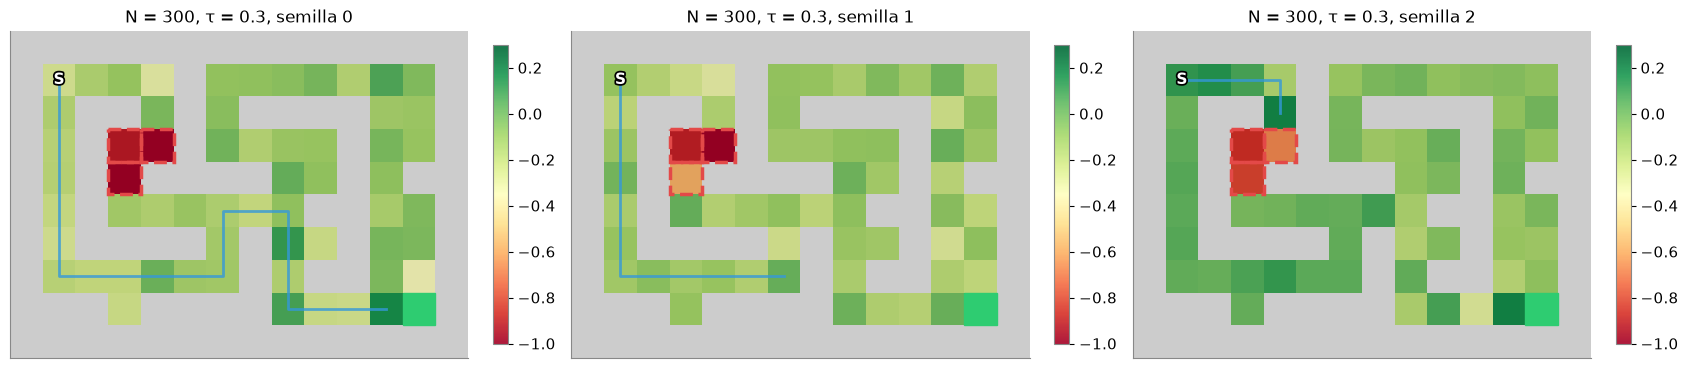

V*(S) = -1.09   π_ref = -3.91


In [19]:
N_ej = 300        # TODO: probá 50, 300, 1000, 3000
tau_ej = 0.3      # TODO: probá 0.05, 0.3, 1, 3

fig, axs = plt.subplots(1, 3, figsize=(17, 4.0))
for s in range(3):
    th_, _ = ajustar_bt(*comparaciones(N_ej, tau_ej, semilla=100 + s))
    r_ = tau_ej * th_
    v_sin = evaluar(plan_greedy(r_), r_escondida)[env.start]
    v_con = evaluar(planificar_con_penalizacion(r_, BETA, pi_ref), r_escondida)[env.start]
    print(f"semilla {s}: correlación {correlacion(r_):.3f}   retorno verdadero sin penalización {v_sin:.2f}   con penalización (β = {BETA}) {v_con:.2f}")
    plot_cave(env, values=r_, ax=axs[s], cmap="RdYlGn", clim=(-1, 0.3), path=camino(plan_greedy(r_)),
              title=f"N = {N_ej}, τ = {tau_ej}, semilla {s}")
    marcar_derrumbe(axs[s])
plt.tight_layout(); plt.show()
print(f"V*(S) = {V_opt[env.start]:.2f}   π_ref = {V_ref_esc:.2f}")

**Lo que encontramos** (¿qué pesa más, $N$ o $\tau$? ¿cuándo el plan sin penalización se queda dando vueltas? ¿la penalización alcanza siempre?):

-

## Preguntas para pensar

1. En la sección 2 comparar acertaba más que puntuar porque el humor del día se cancelaba. ¿Qué otras cosas se cancelan al comparar dos respuestas de un chatbot, y cuáles no (por ejemplo, que a la persona le gusten las respuestas largas)?
2. En la sección 6, el optimizador sin freno encontró una casilla con premio inventado. En un modelo de lenguaje, ¿qué sería esa «casilla»? Piensen en respuestas que a un modelo de recompensa le gustan y a una persona no.
3. La penalización deja a la política cerca de $\pi_{\text{ref}}$. ¿Qué pasa si $\pi_{\text{ref}}$ es mala de entrada? ¿Puede RLHF arreglar algo que la política imitada nunca hace?

## Próxima clase

Todo esto se inventó para ajustar modelos de lenguaje. En la clase 13, **el modelo de lenguaje como política**: el estado es el texto escrito hasta ahora, la acción es el próximo token, la temperatura es una manera de explorar, y la política se ajusta con un grupo de respuestas y un verificador (GRPO).